# Sprint 14 — Sure Tomorrow

Presentation notebook. Implementation lives in `src/`; this notebook imports and presents T1–T4.

**Seed:** 42 everywhere (draws, matrix \(P\), train/test split).
**Core:** pure NumPy after `load_arrays` (sole pandas boundary).


In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt

# repo root on path when the kernel cwd is notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import load_arrays, COLUMN_NAMES
from src.distances import distances
from src.models import linreg_ols, dummies, knn_f1_sweep
from src.obfuscation import obfuscate
from src.diagnostics import (
    f1_vs_k,
    residuals_vs_fitted,
    age_binned_residual_means,
    pairplot,
    correlation_heatmap,
)

SEED = 42
np.random.seed(SEED)
DATA_PATH = ROOT / "data" / "insurance_us.csv"
print("numpy", np.__version__)
print("data", DATA_PATH)


numpy 1.21.6
data /Users/Aldo/Documents/Tripleten/Sprint14/data/insurance_us.csv


## Load

Age is integer in the source and stored as float64 inside the feature matrix. Insurance benefits never enter the feature block.


In [2]:
X, y, y_bin, cols, stats = load_arrays(str(DATA_PATH))
print("columns:", cols)
print("X", X.shape, X.dtype, "| y", y.shape, "| y_bin", y_bin.shape)
print("n =", stats["n"], "| positive_rate =", round(stats["positive_rate"], 4))
print("age quantiles:", stats["age_quantiles"])
print("salary quantiles:", stats["salary_quantiles"])
print("benefit value counts:", dict(zip(*np.unique(y, return_counts=True))))


columns: ['gender', 'age', 'salary', 'family_members']
X (5000, 4) float64 | y (5000,) | y_bin (5000,)
n = 5000 | positive_rate = 0.1128
age quantiles: [18. 24. 30. 37. 65.]
salary quantiles: [ 5300. 33300. 40200. 46600. 79000.]
benefit value counts: {0: 4436, 1: 423, 2: 115, 3: 18, 4: 7, 5: 1}


## Exploratory figures

Pairwise plot and correlation heatmap (from `diagnostics.py`). Age does almost all of the linear work; benefits are zero-inflated.


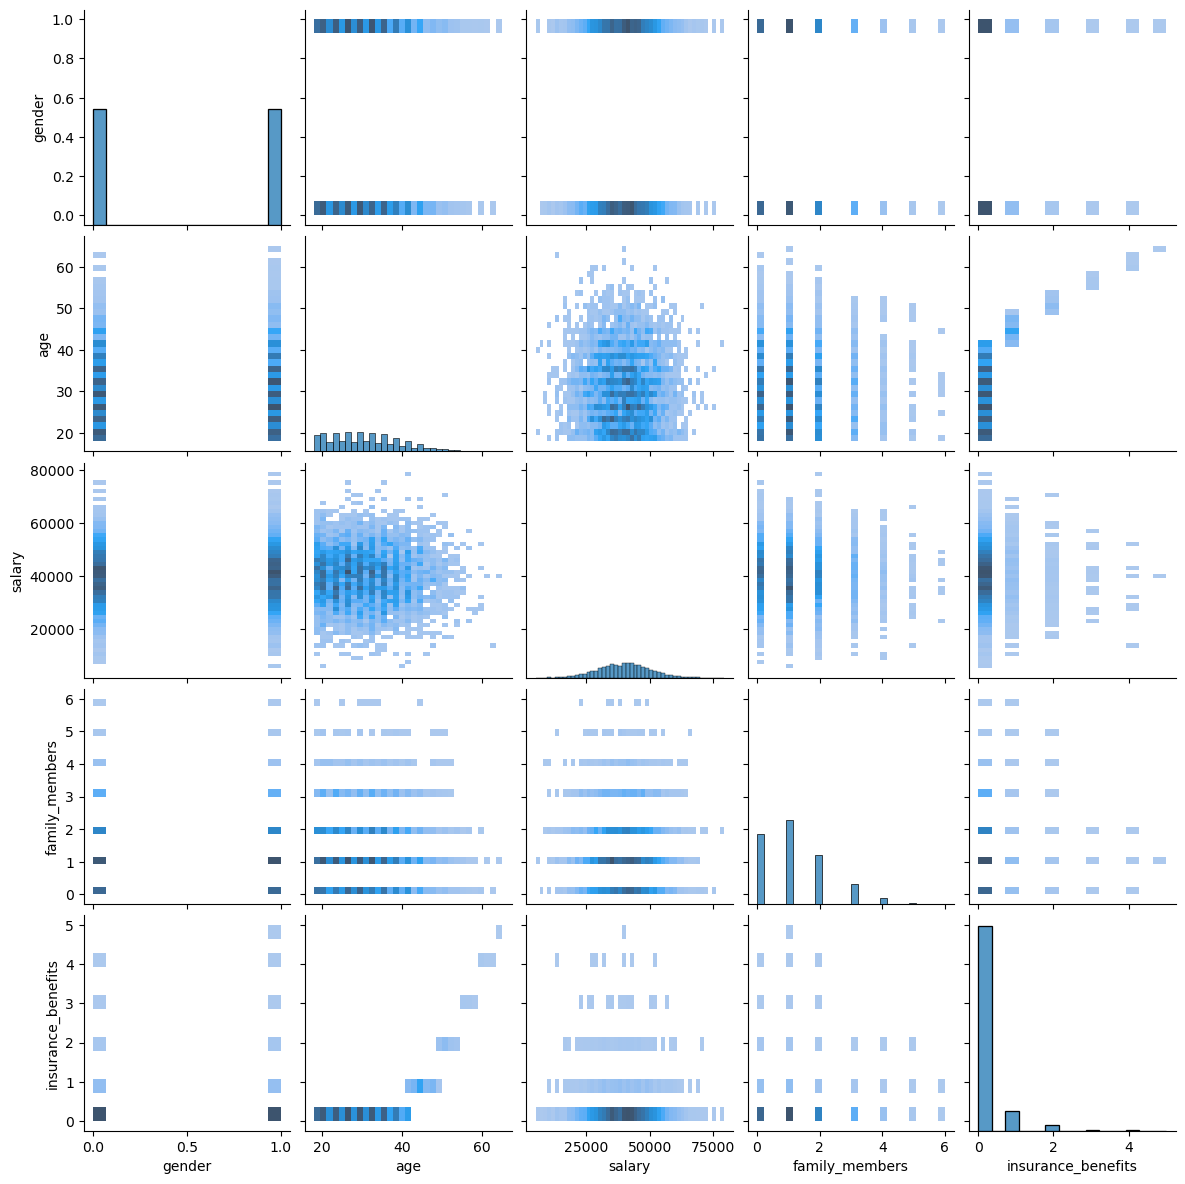

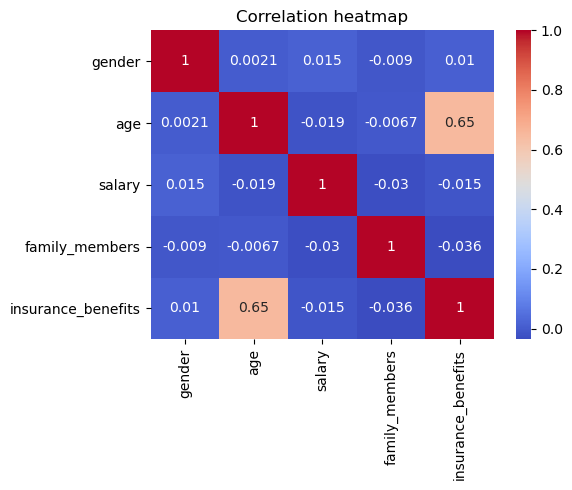

In [3]:
g = pairplot(X, y, cols)
plt.show()

fig_corr = correlation_heatmap(X, y, cols)
plt.show()


## Explicit non-claims (read before the tasks)

1. **Linear regression** on this zero-inflated, age-stepped count produces impossible negative or fractional predictions; residual diagnostics exist to make that fact visible.
2. **Unscaled Euclidean distance** is dominated by salary and is not usable for marketing.
3. **Matrix obfuscation** protects only against casual inspection; knowledge of \(P\) recovers the original data exactly.
4. **No** model-selection, production, or regulatory claims are made.


## T1 — Similarity (four scenarios only)

Keys: `euclidean_raw`, `euclidean_scaled`, `manhattan_raw`, `manhattan_scaled`.  
\(k=5\). Queries are constructed here and passed into `distances` — never invented inside the function.

Contribution shares: Manhattan \(|\Delta_i|/\sum|\Delta_j|\); Euclidean \((\Delta_i)^2/\sum(\Delta_j)^2\).


In [4]:
# Demonstration queries from descriptive ranges + a salary-dominance probe.
age_q = stats["age_quantiles"]
sal_q = stats["salary_quantiles"]

# Extreme age, median-ish salary/family
q1 = np.array([1.0, age_q[4], sal_q[2], 1.0], dtype=np.float64)
# Median age, extreme family members
q2 = np.array([0.0, age_q[2], sal_q[2], 6.0], dtype=np.float64)
# Salary-dominance probe: same age/family as a typical row, large salary gap
q3 = np.array([0.0, age_q[2], sal_q[4] + 10000.0, 1.0], dtype=np.float64)

def as_plain(names, values, ndigits=None):
    """Dict of Python floats so prints stay readable (no np.float64)."""
    out = {}
    for k, v in zip(names, values):
        x = float(v)
        out[k] = round(x, ndigits) if ndigits is not None else x
    return out

queries = [q1, q2, q3]
for i, q in enumerate(queries, 1):
    print(f"query{i}:", as_plain(COLUMN_NAMES, q))

nn = distances(X, queries, k=5)
assert set(nn.keys()) == {
    "euclidean_raw", "euclidean_scaled", "manhattan_raw", "manhattan_scaled"
}

def show_neighbors(scenario, query_idx):
    print("=" * 70)
    print(f"{scenario} | query {query_idx + 1}")
    for rank, nb in enumerate(nn[scenario][query_idx], 1):
        print(f"  #{rank} idx={nb.index} dist={nb.distance:.4f}")
        print(f"      features={as_plain(COLUMN_NAMES, nb.features)}")
        print(
            f"      shares  ={as_plain(COLUMN_NAMES, nb.shares, ndigits=4)}"
            f"  (sum={float(nb.shares.sum()):.4f})"
        )

for scenario in nn:
    show_neighbors(scenario, 0)  # first query for each scenario
    show_neighbors(scenario, 2)  # salary-dominance probe

print("\nNon-claim: unscaled Euclidean shares are salary-dominated — not usable for marketing.")


query1: {'gender': 1.0, 'age': 65.0, 'salary': 40200.0, 'family_members': 1.0}
query2: {'gender': 0.0, 'age': 30.0, 'salary': 40200.0, 'family_members': 6.0}
query3: {'gender': 0.0, 'age': 30.0, 'salary': 89000.0, 'family_members': 1.0}
euclidean_raw | query 1
  #1 idx=954 dist=19.1050
      features={'gender': 1.0, 'age': 46.0, 'salary': 40200.0, 'family_members': 3.0}
      shares  ={'gender': 0.0, 'age': 0.989, 'salary': 0.0, 'family_members': 0.011}  (sum=1.0000)
  #2 idx=40 dist=23.0217
      features={'gender': 1.0, 'age': 42.0, 'salary': 40200.0, 'family_members': 0.0}
      shares  ={'gender': 0.0, 'age': 0.9981, 'salary': 0.0, 'family_members': 0.0019}  (sum=1.0000)
  #3 idx=2590 dist=27.0370
      features={'gender': 0.0, 'age': 38.0, 'salary': 40200.0, 'family_members': 0.0}
      shares  ={'gender': 0.0014, 'age': 0.9973, 'salary': 0.0, 'family_members': 0.0014}  (sum=1.0000)
  #4 idx=1549 dist=27.0370
      features={'gender': 0.0, 'age': 38.0, 'salary': 40200.0, 'family_m

## T2 — Binary classification

Target: `insurance_benefits > 0`. 70/30 split (seed 42).  
kNN sweep \(k=1\ldots10\) on raw and MaxAbs-scaled features lives **in this notebook**; `f1_vs_k` only plots.  
Dummy baselines: probability 0, empirical rate, 0.5, 1.


train (3500, 4) test (1500, 4)
class imbalance: positive_rate overall = 0.1128
positive_rate train/test = 0.1129 0.1127
k | F1 raw | F1 scaled
 1 | 0.6403 | 0.9677
 2 | 0.6340 | 0.9543
 3 | 0.4472 | 0.9362
 4 | 0.4478 | 0.9240
 5 | 0.2524 | 0.9305
 6 | 0.2547 | 0.9277
 7 | 0.1587 | 0.9259
 8 | 0.2051 | 0.9212
 9 | 0.0787 | 0.9154
10 | 0.1105 | 0.9202

Dummy baselines on the test labels:
  p_0: F1=0.0000  CM(tn,fp,fn,tp)=(0.887,0.000,0.113,0.000)
  p_rate: F1=0.1153  CM(tn,fp,fn,tp)=(0.782,0.105,0.099,0.013)
  p_0.5: F1=0.1751  CM(tn,fp,fn,tp)=(0.437,0.450,0.059,0.054)
  p_1: F1=0.2025  CM(tn,fp,fn,tp)=(0.000,0.887,0.000,0.113)


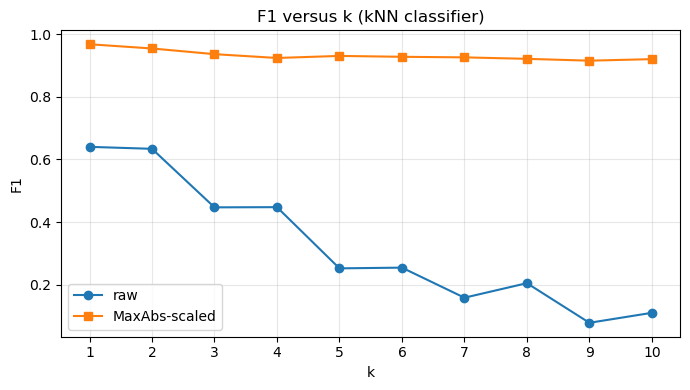

In [5]:
rng = np.random.RandomState(SEED)
n = X.shape[0]
perm = rng.permutation(n)
split = int(0.7 * n)
train_idx, test_idx = perm[:split], perm[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y_bin[train_idx], y_bin[test_idx]

print("train", X_train.shape, "test", X_test.shape)
print("class imbalance: positive_rate overall =", round(stats["positive_rate"], 4))
print("positive_rate train/test =",
      round(float(y_train.mean()), 4), round(float(y_test.mean()), 4))

# MaxAbs on train; apply same scales to test
scale = np.max(np.abs(X_train), axis=0)
scale = np.where(scale == 0.0, 1.0, scale)
X_train_s = X_train / scale
X_test_s = X_test / scale

ks = range(1, 11)
f1_raw = knn_f1_sweep(X_train, y_train, X_test, y_test, ks=ks)
f1_scaled = knn_f1_sweep(X_train_s, y_train, X_test_s, y_test, ks=ks)

print("k | F1 raw | F1 scaled")
for k, a, b in zip(ks, f1_raw, f1_scaled):
    print(f"{k:2d} | {a:.4f} | {b:.4f}")

dummy_metrics = dummies(y_test, seed=SEED)
print("\nDummy baselines on the test labels:")
for name, m in dummy_metrics.items():
    print(f"  {name}: F1={m['f1']:.4f}  CM(tn,fp,fn,tp)=({m['tn']:.3f},{m['fp']:.3f},{m['fn']:.3f},{m['tp']:.3f})")

fig_f1 = f1_vs_k(f1_raw, f1_scaled)
plt.show()


## T3 — Linear regression (custom OLS)

Normal-equation OLS in pure NumPy. Design matrix has a leading column of ones.  
**Predictions are raw reals — never truncated.** RMSE on original and MaxAbs-scaled features. Residual diagnostics make the misspecification visible.


weights (raw, intercept first): [-0.938236  0.007926  0.035708 -0.       -0.013568]
RMSE raw   = 0.3512077581960692
RMSE scaled= 0.3512077581960692
prediction support: min/max = -0.36895398939254964 1.3704102698615066
fraction negative preds = 0.3612
fraction non-integral preds = 1.0


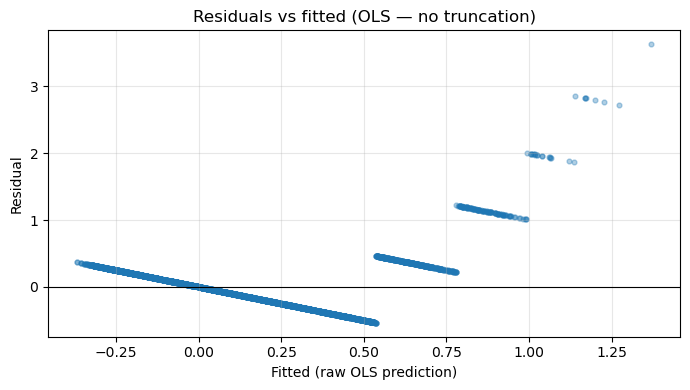

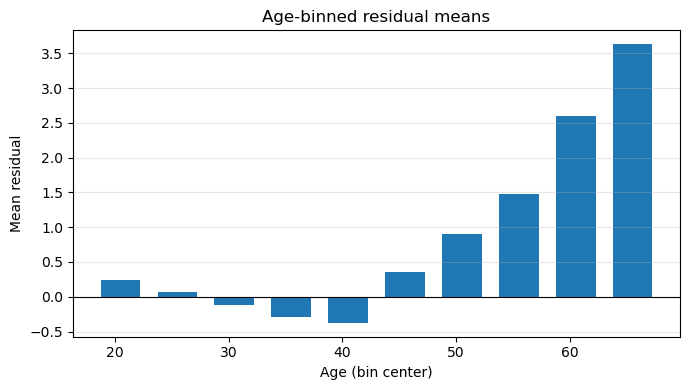

Non-claim: OLS on this DGP yields impossible negative/fractional predictions;
the residual plots exist to keep that fact visible. Not claimed appropriate.


In [6]:
ols_raw = linreg_ols(X, y, scale=False)
ols_scaled = linreg_ols(X, y, scale=True)

print("weights (raw, intercept first):", np.round(ols_raw.weights, 6))
print("RMSE raw   =", ols_raw.rmse)
print("RMSE scaled=", ols_scaled.rmse)
print("prediction support: min/max =",
      float(ols_raw.predictions.min()), float(ols_raw.predictions.max()))
print("fraction negative preds =", float(np.mean(ols_raw.predictions < 0)))
print("fraction non-integral preds =",
      float(np.mean(np.abs(ols_raw.predictions - np.round(ols_raw.predictions)) > 1e-8)))

fig_rvf = residuals_vs_fitted(y, ols_raw.predictions)
plt.show()

resid = y.astype(np.float64) - ols_raw.predictions
fig_age = age_binned_residual_means(X[:, 1], resid)
plt.show()

print("Non-claim: OLS on this DGP yields impossible negative/fractional predictions;")
print("the residual plots exist to keep that fact visible. Not claimed appropriate.")


## T4 — Data obfuscation

Random invertible \(P\) (seed 42) applied to the **feature block only**.  
Intercept ones column is built inside `linreg_ols` and is **never** multiplied by \(P\).

Analytic identity: if \(A=[\mathbf{1}\mid X]\) and \(Q=\mathrm{block\text{-}diag}(1,P)\), then \(A'=AQ=[\mathbf{1}\mid XP]\) spans the same column space, so OLS projections (hence predictions and RMSE) coincide. Knowledge of \(P\) recovers \(X\) exactly via \(P^{-1}\).


In [7]:
obf = obfuscate(X, y)

print("P shape:", obf.P.shape, "| det(P) =", float(np.linalg.det(obf.P)))
print("pred_diff =", obf.pred_diff, "| rmse_diff =", obf.rmse_diff)
print("recovery max|X - X_recovered| =",
      float(np.max(np.abs(X - obf.X_recovered))))
assert obf.pred_diff < 1e-8
assert obf.rmse_diff < 1e-8
assert np.allclose(X, obf.X_recovered, atol=1e-8)

print("\nNon-claim: this is a rudimentary primer, not a compliance solution.")
print("Knowledge of P recovers the original features exactly.")


P shape: (4, 4) | det(P) = -1.8638200811885155
pred_diff = 1.1399770016851107e-12 | rmse_diff = 1.7208456881689926e-15
recovery max|X - X_recovered| = 2.1827872842550278e-11

Non-claim: this is a rudimentary primer, not a compliance solution.
Knowledge of P recovers the original features exactly.


## Conclusions

| Task | What we showed | Caveat that stays visible |
|------|----------------|---------------------------|
| T1 | Four distance scenarios + contribution shares | Unscaled Euclidean ≈ salary match |
| T2 | kNN \(k=1\ldots10\) vs four dummy baselines; class imbalance stated | No model-selection claim |
| T3 | Custom OLS + RMSE raw/scaled + residual diagnostics | Negative/fractional preds remain |
| T4 | Invertible \(P\), prediction identity, exact recovery | Casual obfuscation only |

Checklist: four T1 scenarios with \(k=5\) and shares; T2 metrics + F1-vs-\(k\); T3 metrics + residuals; matrix proof + numerical check; every limitation stated. No production, regulatory, or model-selection claims.
